In [1]:
import numpy as np
import time
import torch
import matplotlib.pyplot as plt
plt.rc('text', usetex=False)
import multiprocessing as mp
from typing import Union


from abc import ABC
from epde.preprocessing.cheb import process_point_cheb

from epde.preprocessing.deriv_calculators import Heatmap, AbstractDeriv, AdaptiveFiniteDeriv, PolynomialDeriv, SpectralDeriv, TotalVariation




In [2]:
def masked_mse(arr1, arr2, inner_start=5, inner_end=27):
    """
    Вычисляет MSE между двумя массивами, игнорируя внутреннюю часть [inner_start:inner_end, inner_start:inner_end].
    
    Параметры:
    ----------
    arr1, arr2 : numpy.ndarray
        Двумерные массивы одинакового размера.
    inner_start, inner_end : int
        Границы внутренней области, которую нужно исключить из расчёта.
        
    Возвращает:
    -----------
    mse : float
        Среднеквадратичная ошибка (без учета внутренней части).
    """
    # Создаём маску: True там, где элементы ДОЛЖНЫ учитываться в MSE (вне внутренней части)
    mask = np.ones_like(arr1, dtype=bool)
    mask[inner_start:inner_end] = False
    
    # Применяем маску к обоим массивам
    masked_arr1 = arr1[mask]
    masked_arr2 = arr2[mask]
    
    # Вычисляем MSE только по валидным элементам
    squared_errors = (masked_arr1 - masked_arr2) ** 2
    mse = np.mean(squared_errors)
    
    return mse

Mean Squared Error (MSE) for noise level 0:
  u_tt: 0.030161533251611646
  u_t: 0.001676994486179614
Mean Squared Error (MSE) for noise level 0.005:
  u_tt: 0.03449638858286327
  u_t: 0.0021171755467114814
Mean Squared Error (MSE) for noise level 0.01:
  u_tt: 0.04285932361816935
  u_t: 0.0033174348749996584


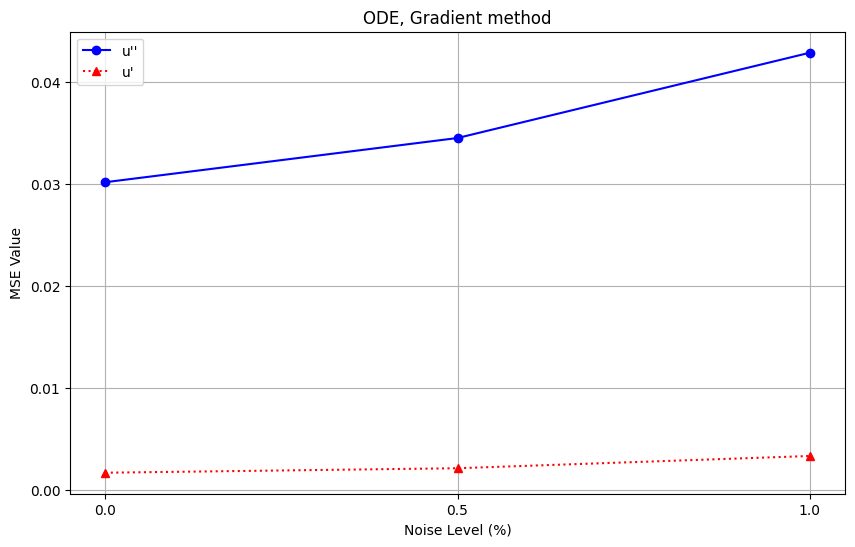

In [4]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_tt = []
mse_values_u_t = []

for noise in noise_levels:
    u_tt = np.load(f'data_ode_noise{noise}_u_tt.npy')
    u_t = np.load(f'data_ode_noise{noise}_u_t.npy')
    
    gradient_tt = np.load(f'ode_Gradient_tt_noise{noise}.npy')
    gradient_t = np.load(f'ode_Gradient_t_noise{noise}.npy')
    
    # Вычисление MSE для каждслучая
    mse_u_tt = masked_mse(u_tt, gradient_tt, inner_start=5, inner_end=27)
    mse_u_t = masked_mse(u_t, gradient_t, inner_start=5, inner_end=27)
    
    mse_values_u_tt.append(mse_u_tt)
    mse_values_u_t.append(mse_u_t)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_tt: {mse_u_tt}')
    print(f'  u_t: {mse_u_t}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_tt, marker='o', linestyle='-', color='b', label="u''")
plt.plot(noise_levels_percent, mse_values_u_t, marker='^', linestyle=':', color='r', label="u'")

plt.title('ODE, Gradient method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('Ode_Gradient_error.pdf', format='pdf')
plt.show()


In [13]:
u_tt.shape

(8,)

Mean Squared Error (MSE) for noise level 0:
  u_tt: 0.4480274697173833
  u_t: 0.022980832382384127
Mean Squared Error (MSE) for noise level 0.005:
  u_tt: 0.4455032032193348
  u_t: 0.022739576613969026
Mean Squared Error (MSE) for noise level 0.01:
  u_tt: 0.4710967074546568
  u_t: 0.027780426927715048


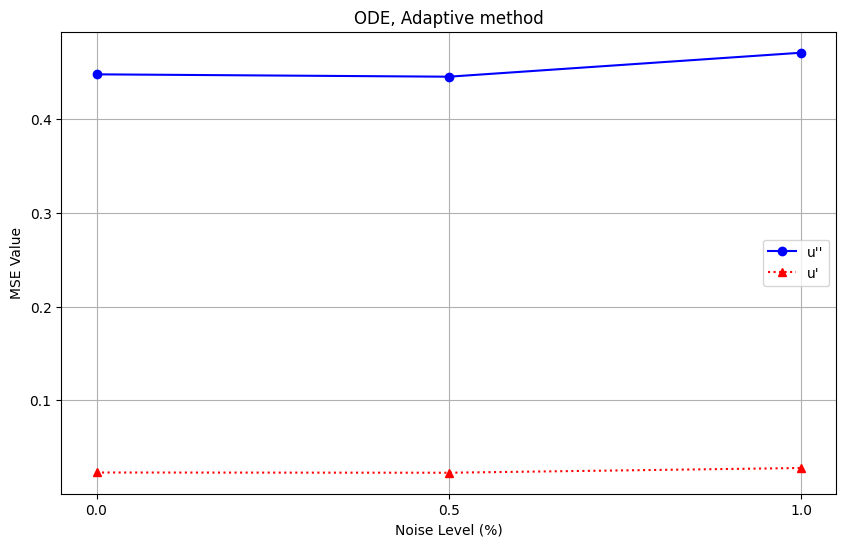

In [5]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_tt = []
mse_values_u_t = []

for noise in noise_levels:
    u_tt = np.load(f'data_ode_noise{noise}_u_tt.npy')
    u_t = np.load(f'data_ode_noise{noise}_u_t.npy')
    
    gradient_tt = np.load(f'ode_Adaptive_tt_noise{noise}.npy')
    gradient_t = np.load(f'ode_Adaptive_t_noise{noise}.npy')

       
    # Вычисление MSE для каждого случая
    mse_u_tt = masked_mse(u_tt, gradient_tt, inner_start=5, inner_end=27)
    mse_u_t = masked_mse(u_t, gradient_t, inner_start=5, inner_end=27)
    
    mse_values_u_tt.append(mse_u_tt)
    mse_values_u_t.append(mse_u_t)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_tt: {mse_u_tt}')
    print(f'  u_t: {mse_u_t}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_tt, marker='o', linestyle='-', color='b', label="u''")
plt.plot(noise_levels_percent, mse_values_u_t, marker='^', linestyle=':', color='r', label="u'")

plt.title('ODE, Adaptive method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('Ode_Adaptive_error.pdf', format='pdf')
plt.show()


Mean Squared Error (MSE) for noise level 0:
  u_tt: 0.05181531306224942
  u_t: 0.04217469126314396
Mean Squared Error (MSE) for noise level 0.005:
  u_tt: 0.07037651623535267
  u_t: 0.041540576698777074
Mean Squared Error (MSE) for noise level 0.01:
  u_tt: 0.09223264773534134
  u_t: 0.049807339630396144


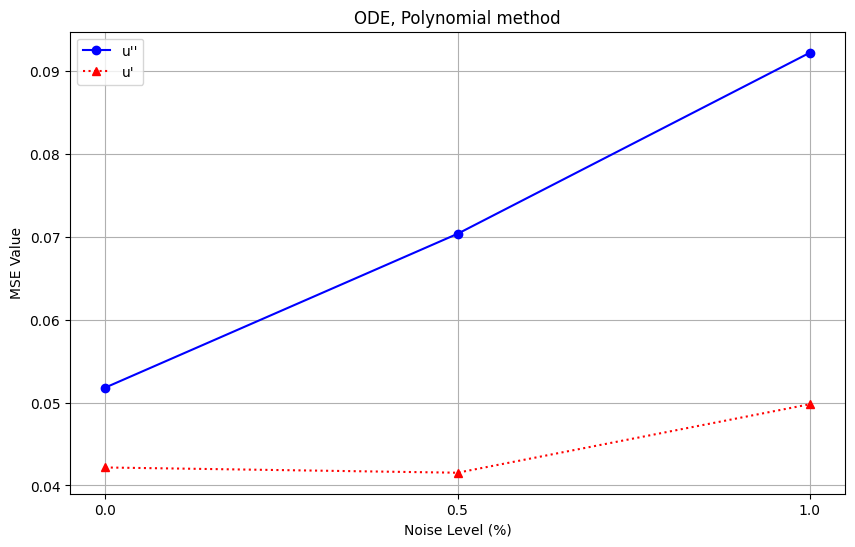

In [6]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_tt = []
mse_values_u_t = []

for noise in noise_levels:
    u_tt = np.load(f'data_ode_noise{noise}_u_tt.npy')
    u_t = np.load(f'data_ode_noise{noise}_u_t.npy')
    
    gradient_tt = np.load(f'ode_Polynomial_tt_noise{noise}.npy')
    gradient_t = np.load(f'ode_Polynomial_t_noise{noise}.npy')
       
    # Вычисление MSE для каждого случая
    mse_u_tt = masked_mse(u_tt, gradient_tt, inner_start=5, inner_end=27)
    mse_u_t = masked_mse(u_t, gradient_t, inner_start=5, inner_end=27)
    
    mse_values_u_tt.append(mse_u_tt)
    mse_values_u_t.append(mse_u_t)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_tt: {mse_u_tt}')
    print(f'  u_t: {mse_u_t}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_tt, marker='o', linestyle='-', color='b', label="u''")
plt.plot(noise_levels_percent, mse_values_u_t, marker='^', linestyle=':', color='r', label="u'")

plt.title('ODE, Polynomial method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('Ode_Polynomial_error.pdf', format='pdf')
plt.show()


Mean Squared Error (MSE) for noise level 0:
  u_tt: 0.6544284308156165
  u_t: 0.23052114432844176
Mean Squared Error (MSE) for noise level 0.005:
  u_tt: 0.6583907362114627
  u_t: 0.23243934313419273
Mean Squared Error (MSE) for noise level 0.01:
  u_tt: 0.6601312278984492
  u_t: 0.23342351182055215


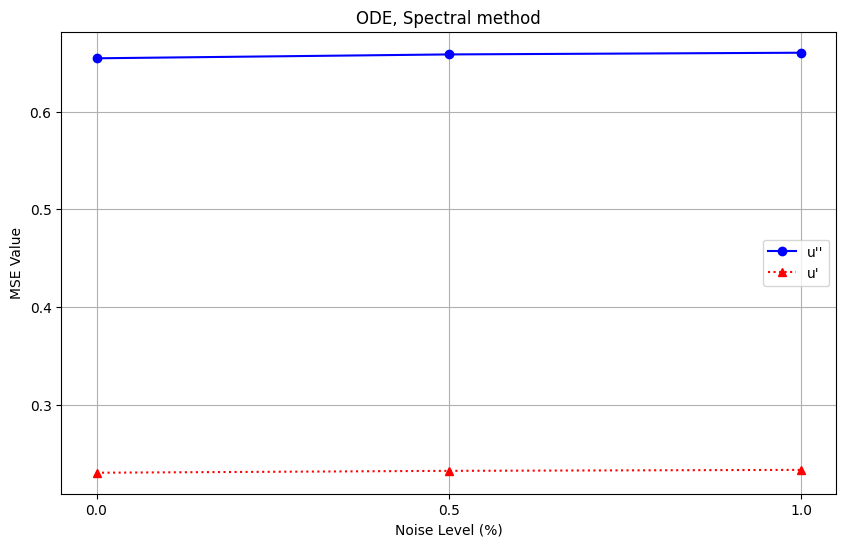

In [7]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_tt = []
mse_values_u_t = []

for noise in noise_levels:
    u_tt = np.load(f'data_ode_noise{noise}_u_tt.npy')
    u_t = np.load(f'data_ode_noise{noise}_u_t.npy')
    
    gradient_tt = np.load(f'ode_Spectral_tt_noise{noise}.npy')
    gradient_t = np.load(f'ode_Spectral_t_noise{noise}.npy')

       
    # Вычисление MSE для каждого случая
    mse_u_tt = masked_mse(u_tt, gradient_tt, inner_start=5, inner_end=27)
    mse_u_t = masked_mse(u_t, gradient_t, inner_start=5, inner_end=27)
    
    mse_values_u_tt.append(mse_u_tt)
    mse_values_u_t.append(mse_u_t)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_tt: {mse_u_tt}')
    print(f'  u_t: {mse_u_t}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_tt, marker='o', linestyle='-', color='b', label="u''")
plt.plot(noise_levels_percent, mse_values_u_t, marker='^', linestyle=':', color='r', label="u'")

plt.title('ODE, Spectral method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('Ode_Spectral_error.pdf', format='pdf')
plt.show()


Mean Squared Error (MSE) for noise level 0:
  u_tt: 4.720793379798086
  u_t: 1.1393193303464317
Mean Squared Error (MSE) for noise level 0.005:
  u_tt: 12.402627705150266
  u_t: 1.1366005513177422
Mean Squared Error (MSE) for noise level 0.01:
  u_tt: 23.77574829755146
  u_t: 1.160600862722123


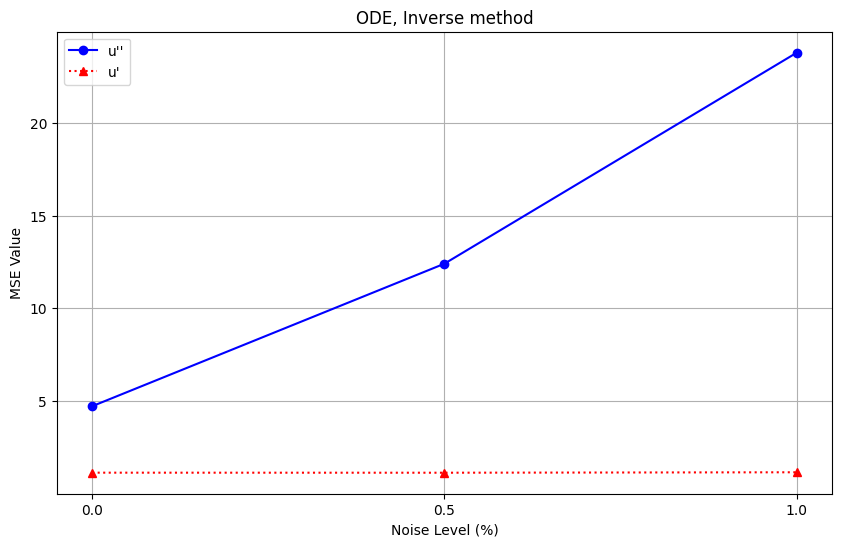

In [8]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_tt = []
mse_values_u_t = []

for noise in noise_levels:
    u_tt = np.load(f'data_ode_noise{noise}_u_tt.npy')
    u_t = np.load(f'data_ode_noise{noise}_u_t.npy')
    
    gradient_tt = np.load(f'ode_Inverse_tt_noise{noise}.npy')
    gradient_t = np.load(f'ode_Inverse_t_noise{noise}.npy')
       
    # Вычисление MSE для каждого случая
    mse_u_tt = masked_mse(u_tt, gradient_tt, inner_start=5, inner_end=27)
    mse_u_t = masked_mse(u_t, gradient_t, inner_start=5, inner_end=27)
    
    mse_values_u_tt.append(mse_u_tt)
    mse_values_u_t.append(mse_u_t)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_tt: {mse_u_tt}')
    print(f'  u_t: {mse_u_t}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_tt, marker='o', linestyle='-', color='b', label="u''")
plt.plot(noise_levels_percent, mse_values_u_t, marker='^', linestyle=':', color='r', label="u'")

plt.title('ODE, Inverse method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('Ode_Inverse_error.pdf', format='pdf')
plt.show()


Mean Squared Error (MSE) for noise level 0:
  u_tt: 2.292046382574908
  u_t: 0.8787257821846778
Mean Squared Error (MSE) for noise level 0.005:
  u_tt: 2.2997849656838363
  u_t: 0.8829039022218079
Mean Squared Error (MSE) for noise level 0.01:
  u_tt: 2.2926399742204167
  u_t: 0.879562553621656


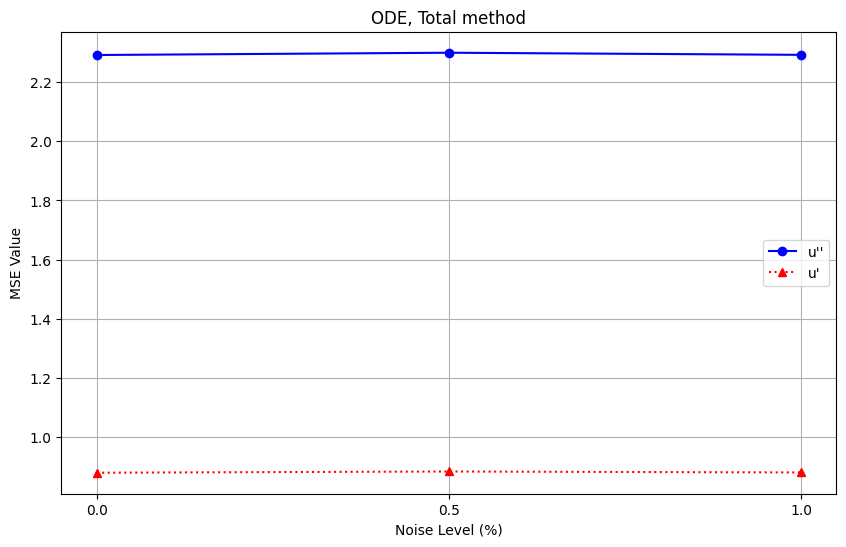

In [9]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_tt = []
mse_values_u_t = []

for noise in noise_levels:
    u_tt = np.load(f'data_ode_noise{noise}_u_tt.npy')
    u_t = np.load(f'data_ode_noise{noise}_u_t.npy')
    
    gradient_tt = np.load(f'ode_Total_tt_noise{noise}.npy')
    gradient_t = np.load(f'ode_Total_t_noise{noise}.npy')
        
    # Вычисление MSE для каждого случая
    mse_u_tt = masked_mse(u_tt, gradient_tt, inner_start=5, inner_end=27)
    mse_u_t = masked_mse(u_t, gradient_t, inner_start=5, inner_end=27)
    
    mse_values_u_tt.append(mse_u_tt)
    mse_values_u_t.append(mse_u_t)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_tt: {mse_u_tt}')
    print(f'  u_t: {mse_u_t}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_tt, marker='o', linestyle='-', color='b', label="u''")
plt.plot(noise_levels_percent, mse_values_u_t, marker='^', linestyle=':', color='r', label="u'")

plt.title('ODE, Total method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('Ode_Total_error.pdf', format='pdf')
plt.show()
